# PMAP-Net training

Run the setup cell in Colab to clone the GitHub repository into `/content` and mount Google Drive. The default run trains on the saved 4×4 BPSK data at 5 dB. It reads `layer_0.csv` through `layer_3.csv` from `MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_4_by_4_BPSK/5dB/`.

Each run saves the model checkpoint and per-layer loss figure in a timestamped Drive folder.

In [1]:
# @title Clone the GitHub repository and mount Drive
from importlib import reload
from pathlib import Path
import subprocess
import sys

from google.colab import drive

REPO_URL = "https://github.com/billlllllllly/EE_MIMO_PROJECT.git"
CODE_ROOT = Path("/content/EE_MIMO_PROJECT")
DRIVE_ROOT = Path("/content/drive/MyDrive/EE_MIMO_PROJECT")

if (CODE_ROOT / ".git").exists():
    origin = subprocess.check_output(
        ["git", "remote", "get-url", "origin"], cwd=CODE_ROOT, text=True
    ).strip()
    if origin != REPO_URL:
        raise RuntimeError(f"{CODE_ROOT} is a clone of {origin}. Set CODE_ROOT to a new directory.")
    subprocess.run(["git", "pull", "--ff-only", "origin", "main"], cwd=CODE_ROOT, check=True)
else:
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", "main", REPO_URL, str(CODE_ROOT)],
        check=True,
    )

trainer_path = CODE_ROOT / "src/models/train_pmapnet.py"
if not trainer_path.is_file():
    raise FileNotFoundError(f"Could not find the trainer in the GitHub checkout at {trainer_path}.")

if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))
for module_name in ("src.models.PMAPnet", "src.models.train_pmapnet"):
    if module_name in sys.modules:
        reload(sys.modules[module_name])
from src.models.train_pmapnet import main as train_pmapnet
if Path(train_pmapnet.__code__.co_filename).resolve() != trainer_path.resolve():
    raise RuntimeError("Restart the Colab runtime to load the trainer from the GitHub checkout.")

drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
# @title Training settings
MODULATION = "bpsk"
NUM_TX = 4
HIDDEN_LAYERS = 5
HIDDEN_WIDTH_MULTIPLIER = 4  # Try 4 to widen every hidden layer.
EPOCHS = 100
BATCH_SIZE = 100
TRAIN_SAMPLES = 20_000
LEARNING_RATE = 0.005
SEED = 42
DEVICE = "auto"  # "auto", "cuda", or "cpu"

LAYER_DATA = "02_colab_output/rayleigh_4_by_4_BPSK/5dB"  # Relative to DRIVE_ROOT
OUTPUT_DIR = DRIVE_ROOT / "02_colab_output"

In [6]:
# @title Train PMAP-Net
arguments = [
    "--modulation", MODULATION,
    "--num-tx", str(NUM_TX),
    "--hidden-layers", str(HIDDEN_LAYERS),
    "--hidden-width-multiplier", str(HIDDEN_WIDTH_MULTIPLIER),
    "--epochs", str(EPOCHS),
    "--batch-size", str(BATCH_SIZE),
    "--train-samples", str(TRAIN_SAMPLES),
    "--learning-rate", str(LEARNING_RATE),
    "--seed", str(SEED),
    "--output-dir", str(OUTPUT_DIR),
    "--layer-data", str(DRIVE_ROOT / LAYER_DATA),
]
if DEVICE != "auto":
    arguments.extend(["--device", DEVICE])

run_dir = train_pmapnet(arguments)

Loading 20,000 BPSK training vectors from /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_4_by_4_BPSK/5dB.
Using cuda. Saving to /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/pmapnet_20261127_174015_054984
Epoch   1/100: row 1 53.122, row 2 59.889, row 3 62.251, row 4 34.967
Epoch   2/100: row 1 36.836, row 2 40.408, row 3 38.579, row 4 0.62404
Epoch   3/100: row 1 34.527, row 2 38.35, row 3 29.894, row 4 0.32958
Epoch   4/100: row 1 30.803, row 2 26.686, row 3 9.9158, row 4 0.20007
Epoch   5/100: row 1 26.594, row 2 13.413, row 3 7.094, row 4 0.17829
Epoch   6/100: row 1 24.999, row 2 10.665, row 3 6.1907, row 4 0.15678
Epoch   7/100: row 1 19.059, row 2 9.5339, row 3 5.8961, row 4 0.14054
Epoch   8/100: row 1 11.898, row 2 8.7769, row 3 5.5085, row 4 0.1258
Epoch   9/100: row 1 9.9663, row 2 7.9225, row 3 5.0949, row 4 0.13561
Epoch  10/100: row 1 9.3824, row 2 7.5063, row 3 4.959, row 4 0.18741
Epoch  11/100: row 1 8.7742, row 2 7.367, row 3 4.4612, row 4 0.

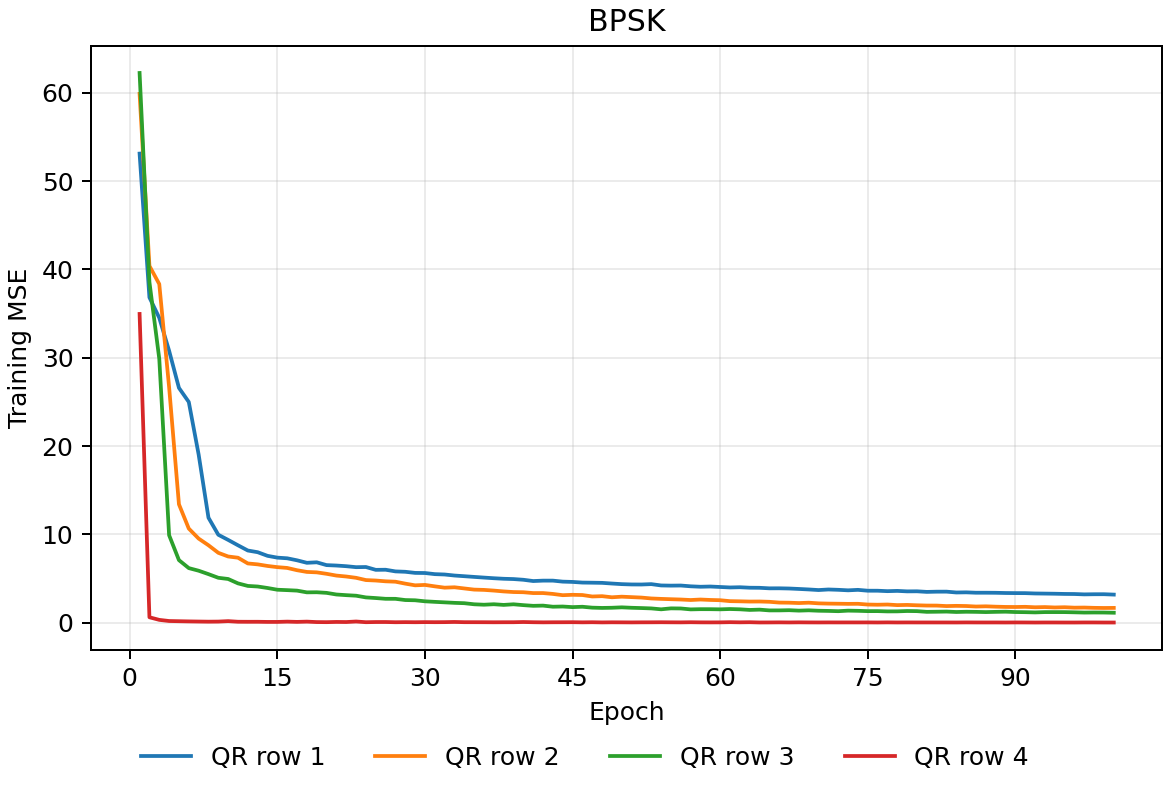

Saved in /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/pmapnet_20261127_174015_054984
pmapnet_bpsk.pt


In [7]:
# @title Show the loss curves and saved files
from IPython.display import Image, display

display(Image(filename=str(run_dir / "layer_loss.png")))
print(f"Saved in {run_dir}")
for checkpoint in sorted(run_dir.glob("pmapnet_*.pt")):
    print(checkpoint.name)